In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF

In [2]:
def test(dmin,dmax):
    res=np.zeros([6,dmax-dmin+1])
    k=0
    for d in np.arange(dmin,dmax+1):
        Y=[(0,1),(1,2.5)]
        n=int((d+1)*(d+2)/2)
        X=[("-inf","inf") for i in range(n)]
        X=np.append(X,[(0,100)],axis=0)
        y0=np.array([[0,1]])
        x0=np.zeros(n+1)
        def fcp(x):
            return x[-1]

        def f(x):
            return np.log(x[0]+x[1])*np.sin(x[0])
    
        def gcp(x,y):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=x[k]*y[0]**i*y[1]**(j-i)
                    k+=1
            return cp.abs(a-f(y))-x[-1]


        def g(x,y):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=x[k]*y[0]**i*y[1]**(j-i)
                    k+=1
            return np.abs(a-f(y))-x[-1]

        def poly(d,coeff,x):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=coeff[k]*x[0]**i*x[1]**(j-i)
                    k+=1
            return a
    
    
        #res[0][k]=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,rho=1)[2]
        res[1][k]=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,drop_cuts=False)[2]
        res[2][k]=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1)[2]
        #res[3][k]=AlgBF(x0,y0,fcp,gcp,g,X,Y)[2]
        res[4][k]=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)[2]
        #res[5][k]=AlgRemez(x0,y0,fcp,gcp,g,X,Y)[2]
        k+=1
    #plt.plot(np.arange(dmin,dmax+1),res[0])
    plt.plot(np.arange(dmin,dmax+1),res[1])
    plt.plot(np.arange(dmin,dmax+1),res[2])
    #plt.plot(np.arange(dmin,dmax+1),res[3])
    plt.plot(np.arange(dmin,dmax+1),res[4])
    #plt.plot(np.arange(dmin,dmax+1),res[5])
    #plt.legend(["Penalization","PenalizationDropCuts", "MePa", "BF","BFDropCuts"])
    plt.legend(["PenalizationDropCuts", "MePa","BFDropCuts"])

Time 7.837277412414551
Time upper problem 6.184419870376587
Time lower problem 1.6528575420379639
Feasibility 0.0006315407874840013
Final rho 1
Rho increases 0
Optimal value -4.990051766319647e-12
Value function call 27
Time 10.796214818954468
Time upper problem 8.98831582069397
Time lower problem 1.8058974742889404
Feasibility -0.0005442276915269091
Optimal value 9.97999294635515e-07
Optimality cuts 1
Feasibility cuts 30
Value function calls 31
Time 9.497756958007812
Time upper problem 7.7365028858184814
Time lower problem 1.7545199394226074
Feasibility 0.00020056368490898766
Optimal value -8.730136270543082e-14
Value function call 29
Time 9.042145729064941
Time upper problem 7.124353408813477
Time lower problem 1.9177923202514648
Feasibility 0.0008311480452611597
Final rho 1
Rho increases 0
Optimal value -5.0026742408242476e-12
Value function call 26
Time 7.976300001144409
Time upper problem 6.19413685798645
Time lower problem 1.782163143157959
Feasibility -0.0002727529115954467
Opti

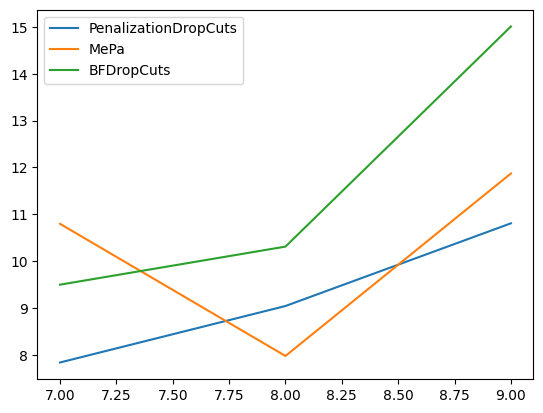

In [4]:
test(7,9)

In [22]:
def test1(d,iters):
    res=np.zeros([6,iters])
    for k in range(iters):
        Y=[(0,1),(1,2.5)]
        n=int((d+1)*(d+2)/2)
        X=[("-inf","inf") for i in range(n)]
        X=np.append(X,[(0,100)],axis=0)
        y0=np.array([[0,1],[0,2.5],[1,1],[1,2.5]])
        x0=np.zeros(n+1)
        alpha=np.random.rand()*4+1
        beta=np.random.rand()*4+1
        gamma=np.random.rand()*4+1
        def fcp(x):
            return x[-1]

        def f(x):
            return np.log(alpha*x[0]+beta*x[1])*np.sin(gamma*x[0])
    
        def gcp(x,y):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=x[k]*y[0]**i*y[1]**(j-i)
                    k+=1
            return cp.abs(a-f(y))-x[-1]


        def g(x,y):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=x[k]*y[0]**i*y[1]**(j-i)
                    k+=1
            return np.abs(a-f(y))-x[-1]

        def poly(d,coeff,x):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=coeff[k]*x[0]**i*x[1]**(j-i)
                    k+=1
            return a
    
    
        #res[0][k]=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,rho=1)[2]
        res[1][k]=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,drop_cuts=False,rho=1)[2]
        res[2][k]=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1)[2]
        #res[3][k]=AlgBF(x0,y0,fcp,gcp,g,X,Y)[2]
        res[4][k]=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=False)[2]
        #res[5][k]=AlgRemez(x0,y0,fcp,gcp,g,X,Y)[2]
        k+=1
    #plt.plot(np.arange(dmin,dmax+1),res[0])
    plt.plot(np.arange(1,k+1),res[1])
    plt.plot(np.arange(1,k+1),res[2])
    #plt.plot(np.arange(dmin,dmax+1),res[3])
    plt.plot(np.arange(1,k+1),res[4])
    #plt.plot(np.arange(dmin,dmax+1),res[5])
    #plt.legend(["Penalization","PenalizationDropCuts", "MePa", "BF","BFDropCuts"])
    plt.legend(["PenalizationDropCuts", "MePa","BFDropCuts"])

In [23]:
test1(7,10)

Time 16.230151653289795
Time upper problem 13.788299798965454
Time lower problem 2.424835443496704
Feasibility 0.0009671132568233598
Final rho 1
Rho increases 0
Optimal value 0.00031106279415387875
Value function call 39
Time 136.76714062690735
Time upper problem 128.97171068191528
Time lower problem 7.794368505477905
Feasibility -1.5266211536834056e-06
Optimal value 0.002014810227143401
Optimality cuts 2
Feasibility cuts 120
Value function calls 122
Time 14.361225128173828
Time upper problem 12.068113088607788
Time lower problem 2.29311203956604
Feasibility 0.0006785659183808998
Optimal value 0.0014293677608323133
Value function call 35
Time 11.109777450561523
Time upper problem 9.089898347854614
Time lower problem 2.019879102706909
Feasibility 0.0008952986453369394
Final rho 1
Rho increases 0
Optimal value -5.907918015195544e-12
Value function call 31
Time 75.4594669342041
Time upper problem 69.692626953125
Time lower problem 5.751765966415405
Feasibility -2.269490298037794e-07
Optim

SolverError: Solver 'MOSEK' failed. Try another solver, or solve with verbose=True for more information.

In [11]:
#X,Y must be a box
Y=[(0,1),(1,2.5)]
d=3
n=int((d+1)*(d+2)/2)
X=[(-10,10) for i in range(n)]
X=np.append(X,[(0,100)],axis=0)

def fcp(x):
    return x[-1]

def f(x):
    return np.log(x[0]+x[1])*np.sin(x[0])
    
def gcp(x,y):
    a=0
    k=0
    for i in range(d+1):
        for j in np.arange(i,d+1):
            a+=x[k]*y[0]**i*y[1]**(j-i)
            k+=1
    return cp.abs(a-f(y))-x[-1]


def g(x,y):
    a=0
    k=0
    for i in range(d+1):
        for j in np.arange(i,d+1):
            a+=x[k]*y[0]**i*y[1]**(j-i)
            k+=1
    return np.abs(a-f(y))-x[-1]

def poly(d,coeff,x):
    a=0
    k=0
    for i in range(d+1):
        for j in np.arange(i,d+1):
            a+=coeff[k]*x[0]**i*x[1]**(j-i)
            k+=1
    return a

In [12]:
y0=np.array([0,1])
x0=np.zeros(n+1)
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y)

SystemError: <built-in function direct> returned a result with an exception set

In [ ]:
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)

In [ ]:
res2=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1)

In [ ]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y)

In [ ]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)

In [8]:
res4=AlgRemez(x0,y0,fcp,gcp,g,X,Y)

Time 24.791351079940796
Time upper problem 22.46619439125061
Time lower problem 2.3251566886901855
Feasibility 9.731900277136496e-07
Optimal value 0.01866200492527265
Value function call 66


In [5]:
coeff=res1[0][:-1]
print(poly(d,coeff,y0))
print(f(y0))

-5.111054745910305e-05
0.0


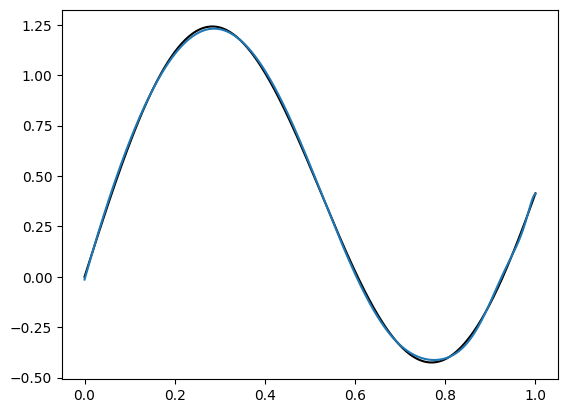

In [71]:
N = 400
x = np.linspace(Y[0][0], Y[0][1], N)


fig, ax = plt.subplots()
ax.plot(x, f(x), "k")
poly1=[poly(n,res1[0],xi) for xi in x]
ax.plot(x, poly1)

#ax.set(aspect=1)